# GEST3032 – Supply Chain Network Resilience with Neo4j

**Central question:** which firms are most critical, and how much does the network suffer when they fail?

Based on the course notebook `neo4j_social_network.ipynb`: same pipeline (generate data → load into Neo4j → Cypher queries → NetworkX algorithms → write back to Neo4j → visualise), but the network is a **supply chain** instead of a social network.

| Social network (course) | Supply network (this project) |
|---|---|
| User | Firm (raw-material supplier, component supplier, assembler, retailer) |
| FOLLOWS | SUPPLIES_TO (with lead time and volume) |
| Celebrity account | Hub supplier serving many customers |
| Community | Region |

**Before running:** Neo4j must be running locally. With Docker, from the `notebooks/` folder:

    docker compose up -d

(Neo4j Browser: http://localhost:7474, user `neo4j`, password `supplychain-pw`.) To stop it: `docker compose down`.

In [ ]:
# Setup: this notebook needs the project venv (Python 3.12), see README section "Python environment"
import sys
if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        f"The kernel is Python {sys.version.split()[0]}, not 3.12. In a terminal at the project root:\n"
        "  winget install Python.Python.3.12\n"
        "  py -3.12 -m venv .venv\n"
        "  .venv\\Scripts\\Activate.ps1\n"
        "  python -m pip install -r requirements.txt\n"
        "then select the .venv kernel (Select Kernel, top right).")

# installs what is missing (does nothing if everything is already installed)
%pip install -q -r ../requirements.txt

## 1. Connect to Neo4j

In the course notebook, Java and Neo4j were installed inside Colab. Here Neo4j runs in Docker, so we only connect to it.

In [1]:
import time
import numpy as np, pandas as pd, networkx as nx, random
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
PW = "supplychain-pw"

driver = None
for _ in range(30):
    try:
        driver = GraphDatabase.driver(URI, auth=("neo4j", PW))
        driver.verify_connectivity()
        break
    except Exception:
        time.sleep(2)
else:
    raise RuntimeError("Neo4j is not reachable: is the Docker container running?")
print("Neo4j is up")

def q(cypher, **params):
    with driver.session() as s:
        return s.run(cypher, **params).data()

Neo4j is up


## 2. Task 1 – Build the supply network

Generator (replaces the stochastic block model of the course):
* **4 tiers**: 15 raw-material suppliers → 20 component suppliers → 20 assemblers → 25 retailers (80 firms).
* **2 regions** (North / South), assigned at random to every firm.
* Each firm buys from **1 to 3 suppliers in the previous tier**, preferably in its own region (85%).
* **3 hub suppliers** in the component tier: 90% of assemblers buy from one of them, and they also sell directly to a few retailers (the only links that skip a tier).
* Each `SUPPLIES_TO` link has a **lead time** (days, +10 when the supplier is in the other region) and a **volume**.

In [2]:
rng = np.random.default_rng(42); random.seed(42)

tiers = [("raw", 15), ("component", 20), ("assembly", 20), ("retail", 25)]
regions = ["North", "South"]

firms = []
for tier, n in tiers:
    for i in range(n):
        firms.append({"id": len(firms), "name": f"{tier.capitalize()}_{i+1:02d}", "tier": tier,
                      "region": regions[int(rng.random() < 0.5)], "is_hub": False})

by_tier = {t: [f for f in firms if f["tier"] == t] for t, _ in tiers}
hubs = by_tier["component"][:3]
for h in hubs:
    h["is_hub"] = True

links = {}
def add(s, t):
    same = s["region"] == t["region"]
    links[(s["id"], t["id"])] = {"lead_time": int(rng.integers(3, 15) + (0 if same else 10)),
                                 "volume": int(rng.integers(100, 1000))}

def pick_suppliers(customer, pool, prefer_hub=False):
    k = int(rng.choice([1, 2, 3], p=[0.35, 0.45, 0.20]))      # number of suppliers
    chosen = []
    if prefer_hub and rng.random() < 0.9:
        chosen.append(hubs[int(rng.integers(len(hubs)))])
    local = [f for f in pool if f["region"] == customer["region"] and f not in chosen]
    other = [f for f in pool if f["region"] != customer["region"] and f not in chosen]
    while len(chosen) < k:
        src = local if (local and rng.random() < 0.85) else (other or local)
        chosen.append(src.pop(int(rng.integers(len(src)))))
    for s in chosen:
        add(s, customer)

for c in by_tier["component"]:
    pick_suppliers(c, list(by_tier["raw"]))
for a in by_tier["assembly"]:
    pick_suppliers(a, [f for f in by_tier["component"] if not f["is_hub"]], prefer_hub=True)
for r in by_tier["retail"]:
    pick_suppliers(r, list(by_tier["assembly"]))

# a few links that skip a tier: hubs also sell directly to retailers
for _ in range(9):
    add(hubs[int(rng.integers(len(hubs)))], by_tier["retail"][int(rng.integers(25))])

edge_rows = [{"s": s, "t": t, **p} for (s, t), p in links.items()]
print(f"{len(firms)} firms, {len(edge_rows)} SUPPLIES_TO links")
pd.crosstab(pd.DataFrame(firms)["tier"], pd.DataFrame(firms)["region"]).loc[[t for t, _ in tiers]]

80 firms, 133 SUPPLIES_TO links


region,North,South
tier,,
raw,9,6
component,10,10
assembly,9,11
retail,12,13


**Question 1:** why did we generate the network this way, and what does the model leave out?

We followed the structure of a manufacturing supply chain: goods flow from raw materials to retail, so most links go from one tier to the next, firms prefer suppliers in their own region (with longer lead times across regions), and 3 component hubs reproduce the "celebrity" accounts of the course notebook, i.e. a few suppliers that many firms depend on. The model leaves out what a real supply chain depends on: capacities and inventories, several products (a link is generic), whether a supplier can be replaced, costs, and changes over time (lead times and volumes are random and not used in the analysis).

### Load into Neo4j (label `Firm`, relationship `SUPPLIES_TO`)

In [3]:
def chunks(xs, n):
    for i in range(0, len(xs), n): yield xs[i:i+n]

q("MATCH (n:Firm) DETACH DELETE n")   # only our firms: the course notebook (User) can stay in the same database
q("CREATE CONSTRAINT firm_id IF NOT EXISTS FOR (f:Firm) REQUIRE f.id IS UNIQUE")

for b in chunks(firms, 1000):
    q("UNWIND $rows AS r MERGE (f:Firm {id: r.id}) "
      "SET f.name = r.name, f.tier = r.tier, f.region = r.region, f.is_hub = r.is_hub", rows=b)
for b in chunks(edge_rows, 2000):
    q("UNWIND $rows AS r MATCH (a:Firm {id: r.s}), (b:Firm {id: r.t}) "
      "MERGE (a)-[l:SUPPLIES_TO]->(b) SET l.lead_time = r.lead_time, l.volume = r.volume", rows=b)

print(q("MATCH (f:Firm) RETURN count(f) AS firms")[0],
      q("MATCH ()-[r:SUPPLIES_TO]->() RETURN count(r) AS supplies_to")[0])

{'firms': 80} {'supplies_to': 133}


## 3. Task 2 – Explore the network with Cypher

**(a) The 5 suppliers with the most direct customers**

In [4]:
pd.DataFrame(q('''
MATCH (f:Firm)
RETURN f.name AS firm, f.tier AS tier, f.region AS region, f.is_hub AS hub,
       COUNT { (f)-[:SUPPLIES_TO]->() } AS customers
ORDER BY customers DESC LIMIT 5'''))

,firm,tier,region,hub,customers
0,Component_03,component,South,True,11
1,Component_01,component,South,True,10
2,Component_02,component,North,True,7
3,Raw_11,raw,South,False,5
4,Assembly_01,assembly,South,False,5


**(b) Firms that rely on a single supplier** (raw-material suppliers have no supplier in the model, so they are excluded)

In [5]:
single = pd.DataFrame(q('''
MATCH (f:Firm) WHERE COUNT { ()-[:SUPPLIES_TO]->(f) } = 1
MATCH (s:Firm)-[:SUPPLIES_TO]->(f)
RETURN f.name AS firm, f.tier AS tier, s.name AS only_supplier, s.is_hub AS supplier_is_hub
ORDER BY only_supplier, firm'''))
print(len(single), "firms rely on a single supplier")
single

17 firms rely on a single supplier


,firm,tier,only_supplier,supplier_is_hub
0,Retail_19,retail,Assembly_01,False
1,Retail_12,retail,Assembly_02,False
2,Retail_23,retail,Assembly_05,False
3,Retail_09,retail,Assembly_07,False
4,Retail_21,retail,Assembly_16,False
5,Assembly_02,assembly,Component_01,True
6,Assembly_14,assembly,Component_01,True
7,Assembly_05,assembly,Component_02,True
8,Assembly_01,assembly,Component_03,True
9,Assembly_04,assembly,Component_03,True


In [6]:
# which suppliers are the "only supplier" most often?
single["only_supplier"].value_counts().head(5)

only_supplier
Component_03    3
Raw_11          3
Component_01    2
Assembly_01     1
Assembly_02     1
Name: count, dtype: int64

**(c) All firms a retailer depends on, up to three tiers upstream**

In [7]:
RETAILER = "Retail_01"

upstream = pd.DataFrame(q('''
MATCH (s:Firm)-[:SUPPLIES_TO*1..3]->(r:Firm {name: $name})
RETURN DISTINCT s.name AS firm, s.tier AS tier, s.region AS region, s.is_hub AS hub
ORDER BY tier, firm''', name=RETAILER))
print(f"{RETAILER} depends on {len(upstream)} firms up to 3 tiers upstream")
upstream

Retail_01 depends on 14 firms up to 3 tiers upstream


,firm,tier,region,hub
0,Assembly_08,assembly,North,False
1,Assembly_10,assembly,North,False
2,Component_02,component,North,True
3,Component_03,component,South,True
4,Component_04,component,North,False
5,Component_06,component,North,False
6,Component_17,component,North,False
7,Raw_03,raw,North,False
8,Raw_04,raw,North,False
9,Raw_05,raw,South,False


**Question 2:** which firms look risky from these queries alone, and why?

* **The 3 hubs** (Component_03, Component_01, Component_02) have the most direct customers (11, 10 and 7) and are also the *only* supplier of 5 assemblers: a failure would immediately stop these firms and, through them, their retailers.
* **Raw_11** is the only supplier of 3 component firms: a small firm, but a single point of failure.
* **The 17 single-source firms** are risky themselves, since they have no alternative supplier.
* **Retail_01** depends on 14 firms up to 3 tiers upstream, including 2 hubs and raw suppliers from the other region (longer lead times).

Limit: these queries only look at direct links (a, b) or a fixed depth (c); they do not measure how far a failure would spread in the whole network, hence Task 3.

## 4. Task 3 – Measure criticality (NetworkX) and write back to Neo4j

As in the course notebook, the graph is read from Neo4j and the algorithms run in NetworkX.

* **PageRank** — in the course, a user is important when many (important) users follow him. Here a firm is critical when many (critical) firms **depend on it**. With the links in the supplier → customer direction, PageRank would give the highest scores to the retailers at the end of the chain, so we compute it on the **reversed graph** (customer → supplier).
* **Betweenness** — share of shortest paths that go through a firm: firms in the middle of many supply paths. The network is small, so it is computed exactly (no sampling as in the course).
* **Louvain** — communities of firms that are densely linked together, compared with the regions (as the course compared them with the planted groups).

In [8]:
from sklearn.metrics import adjusted_rand_score

rows = q("MATCH (a:Firm)-[:SUPPLIES_TO]->(b:Firm) RETURN a.id AS s, b.id AS t")
DG = nx.DiGraph([(r["s"], r["t"]) for r in rows])
DG.add_nodes_from(f["id"] for f in firms)
UG = DG.to_undirected()

pagerank    = nx.pagerank(DG.reverse())
betweenness = nx.betweenness_centrality(DG)
communities = nx.community.louvain_communities(UG, seed=42)
comm_of = {n: i for i, c in enumerate(communities) for n in c}

truth = [f["region"] for f in firms]
found = [comm_of[f["id"]] for f in firms]
print(f"Louvain found {len(communities)} communities; ARI vs regions = {adjusted_rand_score(truth, found):.3f}")
print(f"modularity = {nx.community.modularity(UG, communities):.3f}")

payload = [{"id": n, "pr": pagerank[n], "bt": betweenness[n], "c": comm_of[n]} for n in DG.nodes]
for b in chunks(payload, 1000):
    q("UNWIND $rows AS r MATCH (f:Firm {id: r.id}) "
      "SET f.pagerank = r.pr, f.betweenness = r.bt, f.community = r.c", rows=b)

Louvain found 7 communities; ARI vs regions = 0.219
modularity = 0.525


Check of the direction choice: PageRank on the original direction ranks the retailers first.

In [9]:
name = {f["id"]: f["name"] for f in firms}
pr_original = nx.pagerank(DG)
[name[n] for n, _ in sorted(pr_original.items(), key=lambda x: -x[1])[:5]]

['Retail_16', 'Retail_18', 'Assembly_09', 'Retail_20', 'Retail_15']

**Top 10 firms by each measure**

In [10]:
scores = pd.DataFrame(q('''
MATCH (f:Firm)
RETURN f.name AS firm, f.tier AS tier, f.is_hub AS hub, f.pagerank AS pagerank,
       f.betweenness AS betweenness, f.community AS community,
       COUNT { (f)-[:SUPPLIES_TO]->() } AS customers'''))

top_pr = scores.nlargest(10, "pagerank")["firm"].tolist()
top_bt = scores.nlargest(10, "betweenness")["firm"].tolist()
top_deg = scores.nlargest(10, "customers")["firm"].tolist()

pd.DataFrame({"PageRank (reversed)": top_pr, "Betweenness": top_bt, "Direct customers": top_deg},
             index=range(1, 11))

,PageRank (reversed),Betweenness,Direct customers
1,Raw_09,Component_03,Component_03
2,Component_03,Component_01,Component_01
3,Raw_05,Component_02,Component_02
4,Component_01,Assembly_07,Raw_11
5,Raw_11,Assembly_11,Assembly_01
6,Component_02,Assembly_10,Raw_03
7,Raw_12,Component_17,Raw_05
8,Raw_15,Assembly_20,Raw_09
9,Raw_03,Assembly_05,Raw_12
10,Raw_14,Component_10,Assembly_05


In [11]:
print("in top 10 of PageRank AND betweenness:", sorted(set(top_pr) & set(top_bt)))
print("in all three top 10:", sorted(set(top_pr) & set(top_bt) & set(top_deg)))
print("tiers in top 10 PageRank:   ", scores.set_index("firm").loc[top_pr, "tier"].value_counts().to_dict())
print("tiers in top 10 betweenness:", scores.set_index("firm").loc[top_bt, "tier"].value_counts().to_dict())

in top 10 of PageRank AND betweenness: ['Component_01', 'Component_02', 'Component_03']
in all three top 10: ['Component_01', 'Component_02', 'Component_03']
tiers in top 10 PageRank:    {'raw': 7, 'component': 3}
tiers in top 10 betweenness: {'component': 5, 'assembly': 5}


**Louvain communities** (queried back from Neo4j, as in the course)

In [12]:
pd.DataFrame(q('''
MATCH (f:Firm)
WITH f.community AS community, f ORDER BY f.pagerank DESC
RETURN community, count(*) AS members,
       sum(CASE WHEN f.region = "North" THEN 1 ELSE 0 END) AS north,
       collect(f.name)[0..3] AS top_by_pagerank
ORDER BY members DESC'''))

,community,members,north,top_by_pagerank
0,4,19,2,"[Raw_05, Component_01, Raw_15]"
1,2,16,16,"[Raw_14, Component_17, Raw_13]"
2,1,13,2,"[Raw_09, Raw_11, Raw_10]"
3,6,10,1,"[Component_03, Raw_06, Component_07]"
4,0,10,9,"[Component_02, Raw_12, Raw_03]"
5,3,8,8,"[Assembly_07, Assembly_11, Assembly_18]"
6,5,4,2,"[Assembly_05, Retail_14, Retail_17]"


**Question 3:** do the measures identify the same firms? Which one do we trust more for supply risk, and why?

**Partly.** The 3 hubs are in the top 10 of all three measures, so they are clearly the most critical firms. Otherwise the measures disagree:
* **PageRank (reversed)** is dominated by raw-material suppliers (7 of the top 10): every firm ultimately depends on them, so the dependence accumulates at the start of the chain.
* **Betweenness** only contains component and assembly firms: raw suppliers and retailers are at the ends of the chain, so no path goes *through* them and their score is 0.
* **Louvain** is not a criticality score: it finds 6 communities that are mostly inside one region (e.g. 19 of 20 firms in the North), which matches the regional preference of the generator.

**For supply risk we trust PageRank (reversed) more:** it measures how much of the network depends on a firm, directly and indirectly, which is what is lost when the firm fails. Betweenness finds bottlenecks in the middle of the chain but ignores raw materials, where a disruption spreads the furthest. In practice we would combine it with the single-supplier query of Task 2.

## 5. Visualise

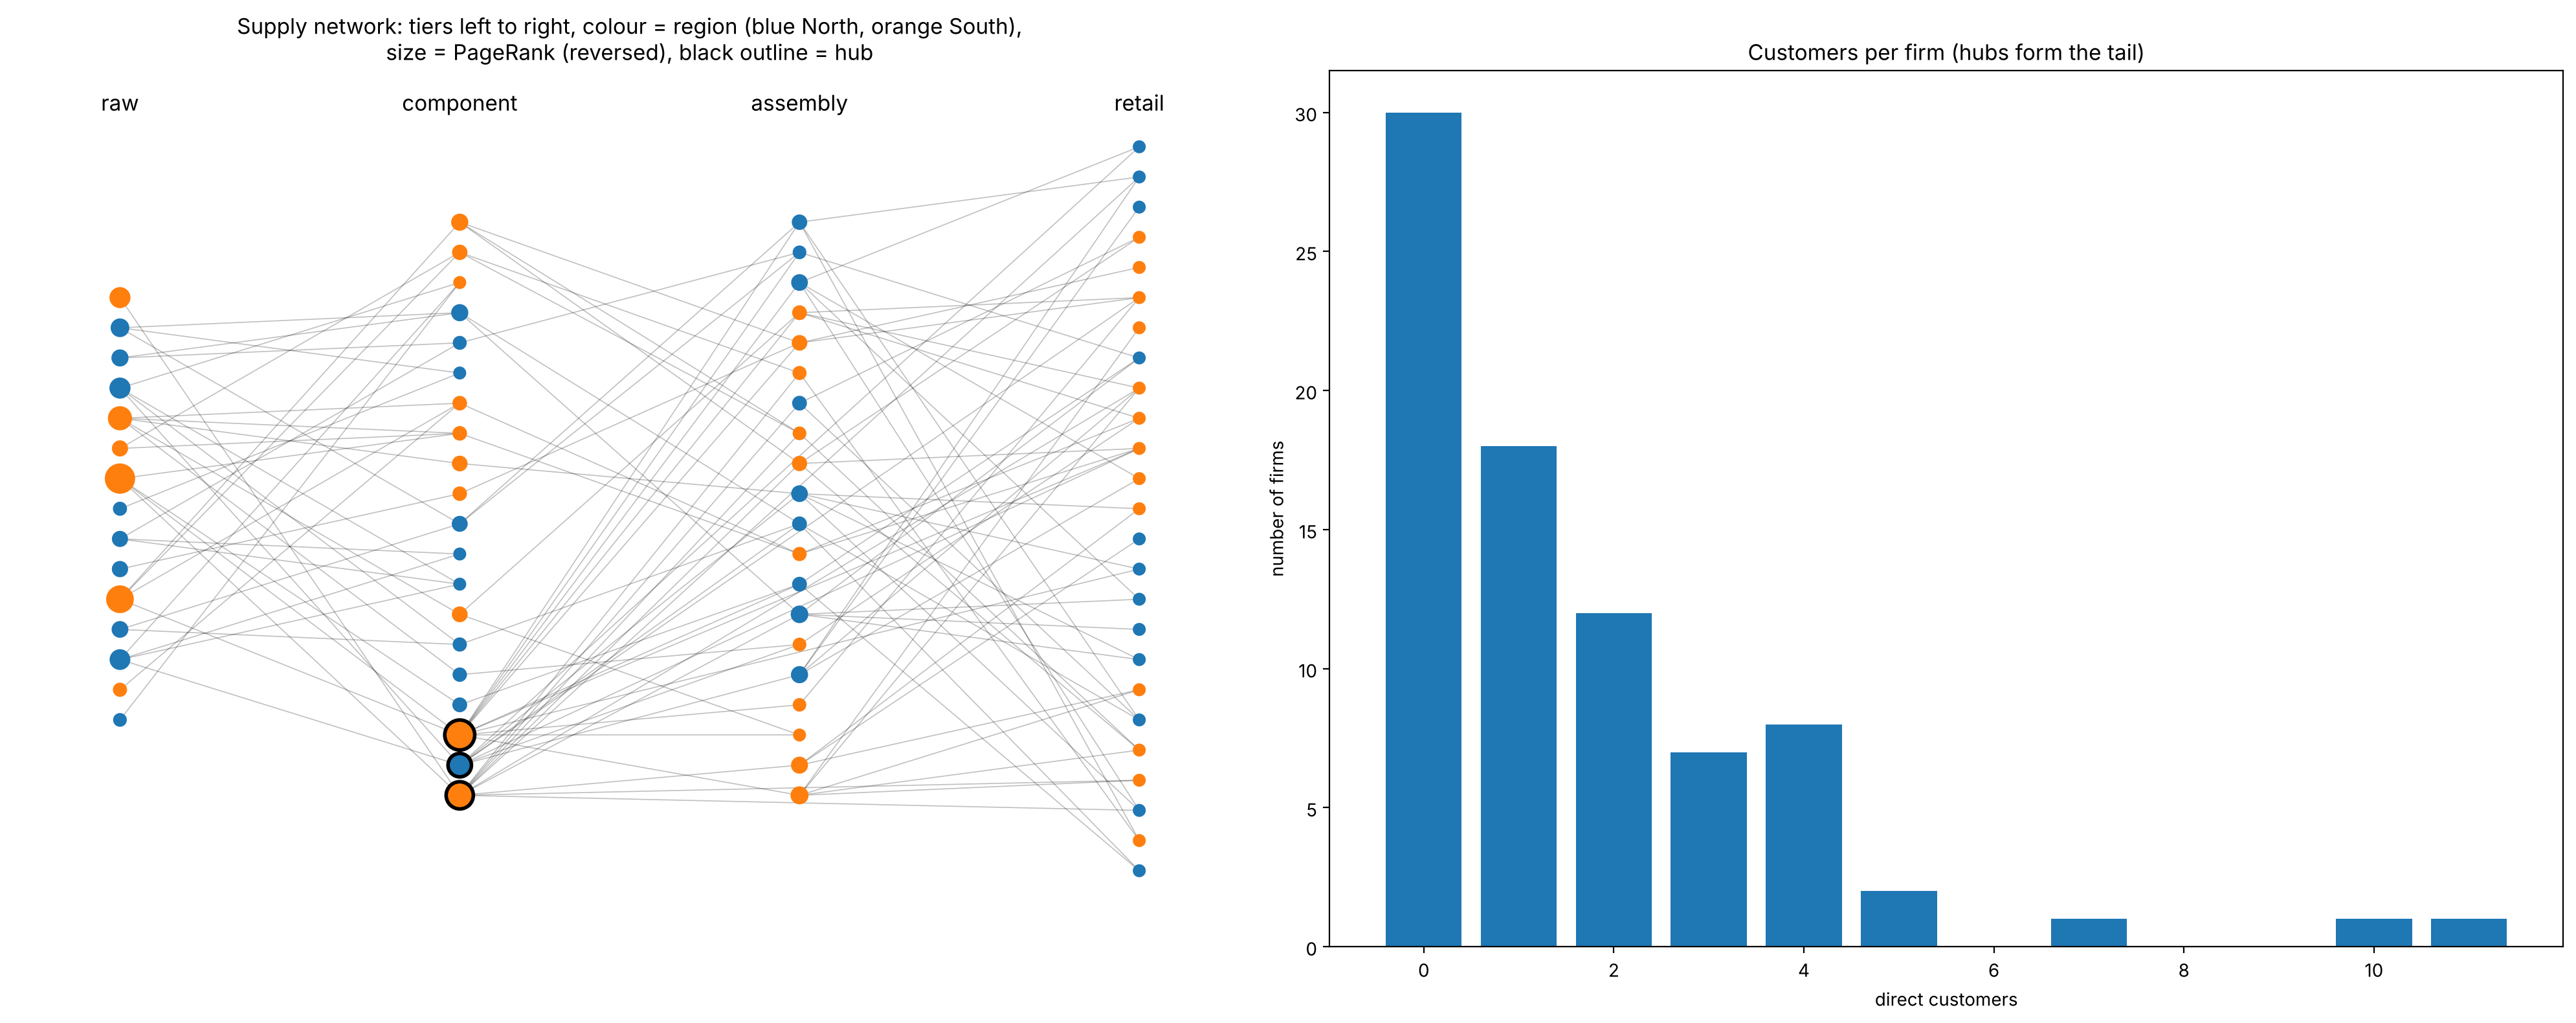

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# (a) Whole network by tier: colour = region, size = PageRank, hubs outlined
for f in firms:
    UG.nodes[f["id"]]["layer"] = [t for t, _ in tiers].index(f["tier"])
pos = nx.multipartite_layout(UG, subset_key="layer")
nodes = list(DG.nodes)
color = ["tab:blue" if firms[n]["region"] == "North" else "tab:orange" for n in nodes]
size = [30 + 4000 * pagerank[n] for n in nodes]
nx.draw_networkx_edges(DG, pos, ax=axes[0], alpha=0.25, width=0.6, arrows=False)
axes[0].scatter([pos[n][0] for n in nodes], [pos[n][1] for n in nodes], c=color, s=size,
                edgecolors=["black" if firms[n]["is_hub"] else "none" for n in nodes], linewidths=2)
for i, (t, _) in enumerate(tiers):
    axes[0].text(pos[by_tier[t][0]["id"]][0], 1.1, t, ha="center", fontsize=12)
axes[0].set_title("Supply network: tiers left to right, colour = region (blue North, orange South),\n"
                  "size = PageRank (reversed), black outline = hub")
axes[0].axis("off")

# (b) Customers per firm (hubs form the tail)
outdeg = pd.Series(dict(DG.out_degree())).value_counts().sort_index()
axes[1].bar(outdeg.index, outdeg.values)
axes[1].set_xlabel("direct customers"); axes[1].set_ylabel("number of firms")
axes[1].set_title("Customers per firm (hubs form the tail)")
plt.tight_layout(); plt.show()

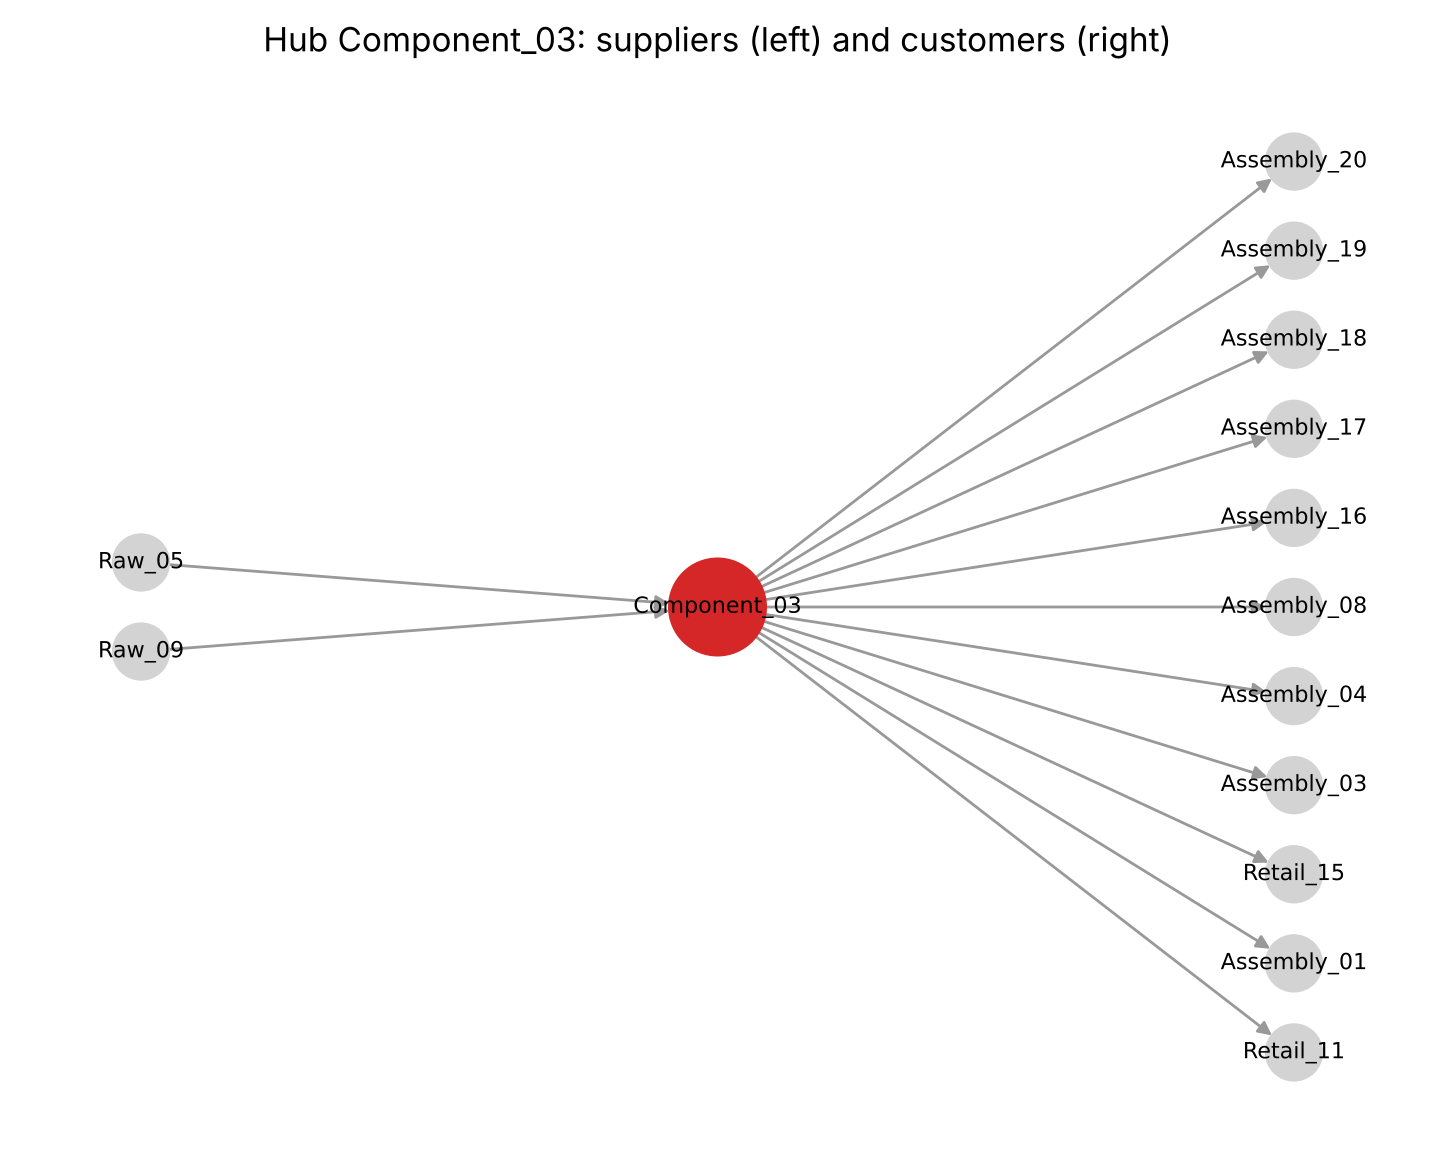

In [14]:
# Ego network of the hub with the most customers: its suppliers and customers
top = max((f["id"] for f in hubs), key=DG.out_degree)
sup, cus = list(DG.predecessors(top)), list(DG.successors(top))
E = DG.subgraph([top] + sup + cus).copy()
for n in E:
    E.nodes[n]["layer"] = 0 if n in sup else (1 if n == top else 2)
plt.figure(figsize=(9, 7))
p2 = nx.multipartite_layout(E, subset_key="layer")
nx.draw_networkx(E, p2, node_color=["tab:red" if n == top else "lightgrey" for n in E],
                 node_size=[1200 if n == top else 400 for n in E],
                 labels={n: name[n] for n in E}, font_size=8, edge_color="#999999")
plt.title(f"Hub {name[top]}: suppliers (left) and customers (right)"); plt.axis("off"); plt.show()

## 6. Shut down

In [15]:
driver.close()
print("connection closed (stop Neo4j with: docker compose down)")

connection closed (stop Neo4j with: docker compose down)
